# 01 — EDA: Exploratory Data Analysis

Understand the three datasets before modelling anything.

**What we have:**
- NewsCLIPpings — 71K pairs (JSON) + pre-extracted CLIP ViT-B/32 & SBERT embeddings
- VERITE — 1K pairs (CSV) + pre-extracted CLIP ViT-L/14 embeddings
- MMFakeBench — ~11K pairs (JSON) + images

**Note:** NewsCLIPpings JSONs do NOT contain captions — captions live in VisualNews images.
The pair JSONs only have `id`, `image_id`, `falsified`, `similarity_score`, `source_dataset`.
All text features come from the pre-extracted SBERT/CLIP text embeddings.

**Sections:**
1. Load & inspect pair JSONs
2. Class balance across datasets
3. OOC sub-type breakdown (NewsCLIPpings)
4. CLIP similarity distribution — why naive CLIP fails
5. VERITE CSV inspection + embedding shapes
6. MMFakeBench inspection
7. Paper-ready summary table

## Setup

In [11]:
import sys, json, pickle, csv
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path("../../").resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
PAPER_FIGS = ROOT / "paper" / "figures"
PAPER_FIGS.mkdir(parents=True, exist_ok=True)

COLORS = {"ooc": "#E05A4B", "genuine": "#4B8AE0", "neutral": "#888888"}
print("Setup done.")
print(f"  ROOT : {ROOT}")

Setup done.
  ROOT : F:\GitHub\eve-rag


## 1. Load & inspect pair JSONs

In [12]:
def load_newsclip(split):
    """Load a NewsCLIPpings split JSON into a DataFrame."""
    fpath = NEWSCLIP / f"{split}.json"
    if not fpath.exists():
        print(f"  ✗  {fpath} not found")
        return pd.DataFrame()
    raw = load_json(fpath)
    pairs = raw.get("annotations", raw) if isinstance(raw, dict) else raw
    df = pd.DataFrame(pairs)
    df["split"] = split
    df["label"] = df["falsified"].astype(int)
    return df

train_df = load_newsclip("train")
val_df   = load_newsclip("val")
test_df  = load_newsclip("test")
all_nc   = pd.concat([train_df, val_df, test_df], ignore_index=True)

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    if df.empty: continue
    ooc = df["label"].sum()
    print(f"  {name:<6} {len(df):>7,} pairs  |  OOC: {ooc:,}  Genuine: {len(df)-ooc:,}  ({ooc/len(df)*100:.1f}% OOC)")
print()
print(f"  Columns: {list(train_df.columns)}")
print(f"  Total  : {len(all_nc):,} pairs")
print()
print("  Note: 'caption' column is NOT here — text features come from SBERT/CLIP pkl files.")

  train   71,072 pairs  |  OOC: 35,536  Genuine: 35,536  (50.0% OOC)
  val      7,024 pairs  |  OOC: 3,512  Genuine: 3,512  (50.0% OOC)
  test     7,264 pairs  |  OOC: 3,632  Genuine: 3,632  (50.0% OOC)

  Columns: ['id', 'image_id', 'similarity_score', 'source_dataset', 'falsified', 'split', 'label']
  Total  : 85,360 pairs

  Note: 'caption' column is NOT here — text features come from SBERT/CLIP pkl files.


## 2. Class balance across datasets

In [13]:
# Load VERITE
verite_file = VERITE / "VERITE.csv"
verite_df = pd.DataFrame()
if verite_file.exists():
    verite_df = pd.read_csv(verite_file)
    # VERITE has 3 classes: out-of-context, miscaptioned, true
    # For binary OOC detection: OOC=1, everything else=0
    if "label" in verite_df.columns:
        verite_df["label_orig"] = verite_df["label"]
        verite_df["label"] = (verite_df["label"].str.lower() == "out-of-context").astype(int)
    print(f"  VERITE loaded: {len(verite_df)} rows")
    print(f"  Columns: {list(verite_df.columns)}")
    print(f"  Label distribution: {dict(Counter(verite_df['label_orig']))}")
else:
    print(f"  ✗  VERITE.csv not found at {verite_file}")

# Load MMFakeBench
mmfake_file = DATA / "mmfakebench" / "MMFakeBench_test.json"
mmfake_df = pd.DataFrame()
if mmfake_file.exists():
    raw = load_json(mmfake_file)
    pairs = raw if isinstance(raw, list) else list(raw.values())
    mmfake_df = pd.DataFrame(pairs)
    mmfake_df["label"] = (mmfake_df["gt_answers"].str.lower() == "fake").astype(int)
    print(f"  MMFakeBench loaded: {len(mmfake_df)} rows")
    print(f"  Labels: {dict(Counter(mmfake_df['gt_answers']))}")
    ooc_mm = mmfake_df[mmfake_df.get("fake_cls", pd.Series()).str.contains("cross_modal", na=False)]
    print(f"  OOC-type (cross_modal_consistency): {len(ooc_mm):,}")
else:
    print(f"  ⚠  MMFakeBench not downloaded yet — skipping")

  VERITE loaded: 1001 rows
  Columns: ['Unnamed: 0', 'caption', 'image_path', 'label', 'label_orig']
  Label distribution: {'true': 338, 'miscaptioned': 338, 'out-of-context': 325}
  MMFakeBench loaded: 10000 rows
  Labels: {'True': 3000, 'Fake': 7000}
  OOC-type (cross_modal_consistency): 0


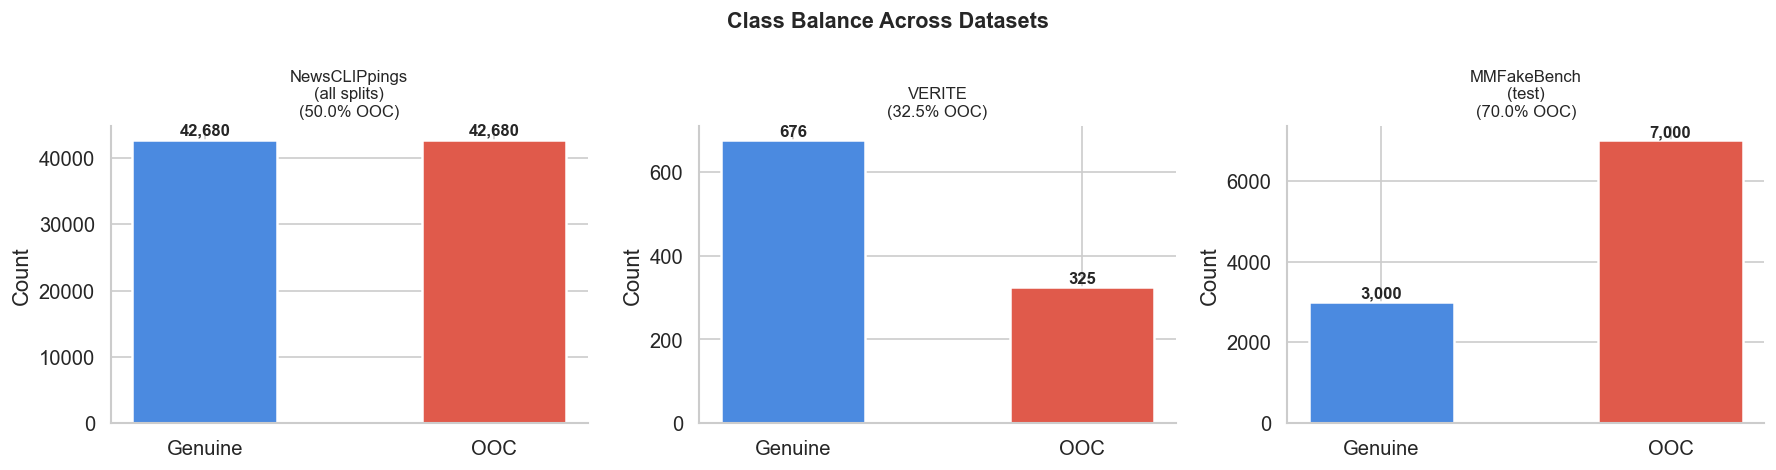

  Saved → paper/figures/eda_class_balance.pdf


In [14]:
# Class balance bar charts
datasets_to_plot = []
if not all_nc.empty:
    datasets_to_plot.append(("NewsCLIPpings\n(all splits)", all_nc))
if not verite_df.empty:
    datasets_to_plot.append(("VERITE", verite_df))
if not mmfake_df.empty:
    datasets_to_plot.append(("MMFakeBench\n(test)", mmfake_df))

if not datasets_to_plot:
    print("No datasets loaded yet.")
else:
    fig, axes = plt.subplots(1, len(datasets_to_plot), figsize=(5*len(datasets_to_plot), 4))
    if len(datasets_to_plot) == 1: axes = [axes]
    fig.suptitle("Class Balance Across Datasets", fontsize=13, fontweight="bold")

    for ax, (name, df) in zip(axes, datasets_to_plot):
        counts = df["label"].value_counts().sort_index()
        bars = ax.bar(["Genuine", "OOC"], [counts.get(0,0), counts.get(1,0)],
                      color=[COLORS["genuine"], COLORS["ooc"]],
                      edgecolor="white", linewidth=1.5, width=0.5)
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + len(df)*0.01,
                    f"{int(bar.get_height()):,}", ha="center", fontsize=10, fontweight="bold")
        pct = counts.get(1,0) / len(df) * 100
        ax.set_title(f"{name}\n({pct:.1f}% OOC)", fontsize=10)
        ax.set_ylabel("Count")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig(PAPER_FIGS / "eda_class_balance.pdf", bbox_inches="tight")
    plt.show()
    print("  Saved → paper/figures/eda_class_balance.pdf")

## 3. NewsCLIPpings — OOC sub-type breakdown

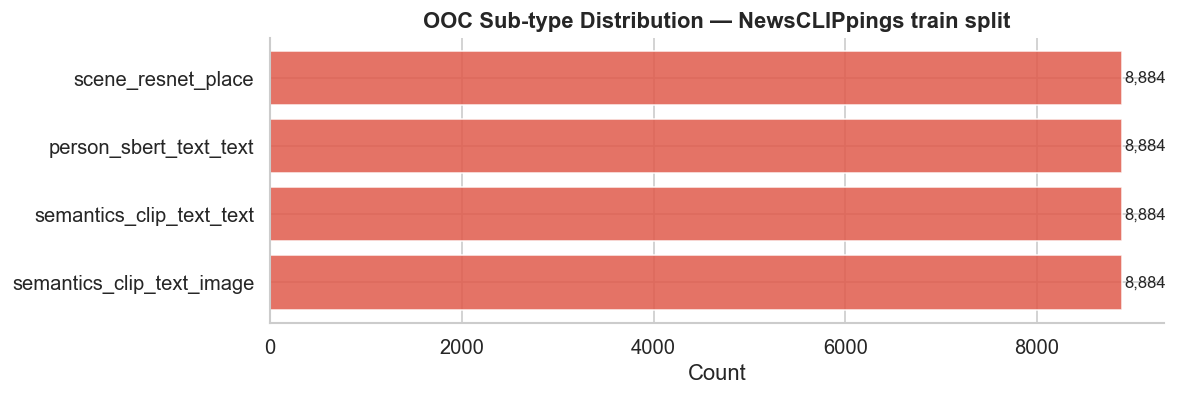


OOC sub-types:
  semantics_clip_text_image                 8,884
  semantics_clip_text_text                  8,884
  person_sbert_text_text                    8,884
  scene_resnet_place                        8,884


In [15]:
# source_dataset column encodes which sub-split the OOC pair came from
if not train_df.empty and "source_dataset" in train_df.columns:
    ooc_only = train_df[train_df["label"] == 1]
    type_counts = ooc_only["source_dataset"].value_counts()

    # Map integer codes to names (from NewsCLIPpings paper)
    # 0=person_sbert_text_text, 1=scene_resnet_place,
    # 2=semantics_clip_text_image, 3=semantics_clip_text_text
    source_names = {
        0: "person_sbert_text_text",
        1: "scene_resnet_place",
        2: "semantics_clip_text_image",
        3: "semantics_clip_text_text",
    }
    type_counts.index = [source_names.get(i, str(i)) for i in type_counts.index]

    fig, ax = plt.subplots(figsize=(10, 3.5))
    bars = ax.barh(type_counts.index, type_counts.values,
                   color=COLORS["ooc"], alpha=0.85, edgecolor="white")
    for bar in bars:
        ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
                f"{int(bar.get_width()):,}", va="center", fontsize=10)
    ax.set_title("OOC Sub-type Distribution — NewsCLIPpings train split", fontweight="bold")
    ax.set_xlabel("Count")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(PAPER_FIGS / "eda_ooc_subtypes.pdf", bbox_inches="tight")
    plt.show()

    print("\nOOC sub-types:")
    for t, c in type_counts.items():
        print(f"  {t:<40}  {c:,}")
else:
    print("  ⚠  source_dataset column not found or train not loaded")

## 4. CLIP similarity distribution — why naive CLIP fails

Loading CLIP test embeddings...
  Computed 7,264 similarities  (0 pairs skipped — id not in embeddings)


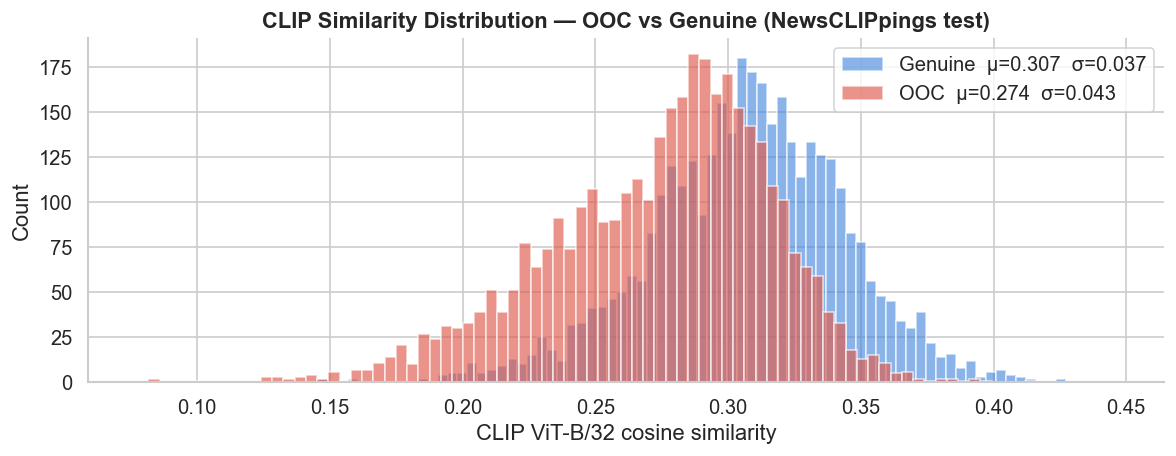


  Best threshold accuracy: 65.8%  at threshold=0.296
  → This is the naive CLIP baseline. Entity verification must beat this.


In [16]:
# Load pre-extracted CLIP embeddings and compute cosine similarity per pair
# This is the KEY motivating figure for the paper.

clip_img_test = CLIP_EMB / "clip_image_embeddings" / "test.pkl"
clip_txt_test = CLIP_EMB / "clip_text_embeddings"  / "test.pkl"

if clip_img_test.exists() and clip_txt_test.exists() and not test_df.empty:
    import torch

    print("Loading CLIP test embeddings...")
    img_embs = pickle.load(open(clip_img_test, "rb"))  # {id: np.array}
    txt_embs = pickle.load(open(clip_txt_test, "rb"))  # {id: np.array}

    # For each test pair: image uses image_id, text uses id (caption's image)
    sims, labels = [], []
    missing = 0
    for _, row in test_df.iterrows():
        img_id = row["image_id"]
        txt_id = row["id"]
        if img_id not in img_embs or txt_id not in txt_embs:
            missing += 1
            continue
        img_v = img_embs[img_id].astype(np.float32)
        txt_v = txt_embs[txt_id].astype(np.float32)
        # cosine similarity
        sim = np.dot(img_v, txt_v) / (np.linalg.norm(img_v) * np.linalg.norm(txt_v) + 1e-8)
        sims.append(sim)
        labels.append(row["label"])

    sims   = np.array(sims)
    labels = np.array(labels)
    print(f"  Computed {len(sims):,} similarities  ({missing} pairs skipped — id not in embeddings)")

    fig, ax = plt.subplots(figsize=(10, 4))
    for lbl, name, color in [(0, "Genuine", COLORS["genuine"]), (1, "OOC", COLORS["ooc"])]:
        subset = sims[labels == lbl]
        ax.hist(subset, bins=80, alpha=0.65, color=color,
                label=f"{name}  μ={subset.mean():.3f}  σ={subset.std():.3f}")
    ax.set_xlabel("CLIP ViT-B/32 cosine similarity")
    ax.set_ylabel("Count")
    ax.set_title("CLIP Similarity Distribution — OOC vs Genuine (NewsCLIPpings test)",
                 fontweight="bold")
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(PAPER_FIGS / "eda_clip_similarity.pdf", bbox_inches="tight")
    plt.show()

    # Naive threshold accuracy
    thresholds = np.linspace(sims.min(), sims.max(), 200)
    accs = [(((sims < t) == labels).mean()) for t in thresholds]
    best_t  = thresholds[np.argmax(accs)]
    best_acc = max(accs)
    print(f"\n  Best threshold accuracy: {best_acc*100:.1f}%  at threshold={best_t:.3f}")
    print(f"  → This is the naive CLIP baseline. Entity verification must beat this.")
else:
    print("  ⚠  CLIP embeddings or test.json not found — run data_download.ipynb first")

## 5. VERITE — CSV inspection + embedding shapes

In [17]:
import numpy as np

print("VERITE CSV:")
if not verite_df.empty:
    print(f"  Rows    : {len(verite_df)}")
    print(f"  Columns : {list(verite_df.columns)}")
    if "label_orig" in verite_df.columns:
        print(f"  Classes : {dict(Counter(verite_df['label_orig']))}")
    print()
    print(verite_df.head(3).to_string())
else:
    print("  ✗  Not loaded")

print()
print("VERITE CLIP ViT-L/14 embeddings:")
for fname in ["image_embeddings.npy", "text_embeddings.npy"]:
    fpath = CLIP_EMB / "verite" / fname
    if fpath.exists():
        arr = np.load(str(fpath))
        print(f"  ✓  {fname:<35} shape={arr.shape}  dtype={arr.dtype}")
        # Compute a quick self-similarity check
        norms = np.linalg.norm(arr, axis=1)
        print(f"     Embedding norms: min={norms.min():.3f}  max={norms.max():.3f}  mean={norms.mean():.3f}")
    else:
        print(f"  ✗  {fname} not found at {fpath}")

print()
print("  Note: VERITE uses ViT-L/14 (dim=768) vs NewsCLIPpings ViT-B/32 (dim=512).")
print("  Both will work — we'll use cosine similarity in both cases.")

VERITE CSV:
  Rows    : 1001
  Columns : ['Unnamed: 0', 'caption', 'image_path', 'label', 'label_orig']
  Classes : {'true': 338, 'miscaptioned': 338, 'out-of-context': 325}

   Unnamed: 0                                                                                                                                                                                                                      caption          image_path  label      label_orig
0           0  Photograph shows a family that was taken away by local epidemic prevention personnel after they had returned home from Hubei Province in February 2020 while they were asked to self-quarantine in their homes for 14 days.   images/true_0.jpg      0            true
1           1                                                                   Photograph shows Chinese officials in white protective hazmat suits carrying people down a hallway to be quarantined for having COVID-19 in November 2022.   images/true_0.jpg      0    misc

## 6. MMFakeBench — inspection

In [18]:
if not mmfake_df.empty:
    print(f"MMFakeBench test set: {len(mmfake_df):,} samples")
    print(f"  Columns      : {list(mmfake_df.columns)}")
    print(f"  Labels       : {dict(Counter(mmfake_df['gt_answers']))}")

    if "fake_cls" in mmfake_df.columns:
        print(f"\n  Misinformation sub-categories:")
        for cls, cnt in mmfake_df["fake_cls"].value_counts().items():
            marker = " ← OOC-type (our target)" if "cross_modal" in str(cls) else ""
            print(f"    {str(cls):<45}  {cnt:>5,}{marker}")

    print(f"\n  Sample entry:")
    print(mmfake_df.iloc[0].to_dict())
else:
    print("  ⚠  MMFakeBench not loaded — download it first")

MMFakeBench test set: 10,000 samples
  Columns      : ['text', 'image_path', 'text_source', 'image_source', 'gt_answers', 'fake_cls', 'label']
  Labels       : {'True': 3000, 'Fake': 7000}

  Misinformation sub-categories:
    original                                       3,000
    textual_veracity_distortion                    3,000
    mismatch                                       3,000
    visual_veracity_distortion                     1,000

  Sample entry:
{'text': 'The abductions sparked protests across the world to demand the release of the girls', 'image_path': '/real/bbc_test_500/bbc_test_0.png', 'text_source': 'VisualNews', 'image_source': 'VisualNews', 'gt_answers': 'True', 'fake_cls': 'original', 'label': 0}


## 7. Paper-ready summary table

In [19]:
rows = []

# NewsCLIPpings splits
for split, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    if df.empty:
        rows.append({"Dataset": f"NewsCLIPpings ({split})", "Split": split,
                     "Total": "N/A", "OOC": "N/A", "Genuine": "N/A", "OOC%": "N/A"})
        continue
    n, ooc = len(df), int(df["label"].sum())
    rows.append({"Dataset": f"NewsCLIPpings ({split})", "Split": split,
                 "Total": f"{n:,}", "OOC": f"{ooc:,}",
                 "Genuine": f"{n-ooc:,}", "OOC%": f"{ooc/n*100:.1f}%"})

# VERITE
if not verite_df.empty:
    n = len(verite_df)
    label_col = "label_orig" if "label_orig" in verite_df.columns else "label"
    ooc_count = int((verite_df[label_col].str.lower() == "out-of-context").sum()) if verite_df[label_col].dtype == object else int(verite_df["label"].sum())
    rows.append({"Dataset": "VERITE", "Split": "zero-shot eval",
                 "Total": f"{n:,}", "OOC": f"{ooc_count:,}",
                 "Genuine": f"{n-ooc_count:,}", "OOC%": f"{ooc_count/n*100:.1f}%"})
else:
    rows.append({"Dataset": "VERITE", "Split": "zero-shot eval",
                 "Total": "N/A", "OOC": "N/A", "Genuine": "N/A", "OOC%": "N/A"})

# MMFakeBench
if not mmfake_df.empty:
    n = len(mmfake_df)
    if "fake_cls" in mmfake_df.columns:
        ooc_mm = int(mmfake_df["fake_cls"].str.contains("cross_modal", na=False).sum())
    else:
        ooc_mm = int(mmfake_df["label"].sum())
    rows.append({"Dataset": "MMFakeBench (OOC subset)", "Split": "zero-shot eval",
                 "Total": f"{n:,}", "OOC": f"{ooc_mm:,}",
                 "Genuine": "N/A", "OOC%": f"{ooc_mm/n*100:.1f}%"})

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print()
print("  → Copy this to paper/tables/ when writing Section 4 (Experiments).")

                 Dataset          Split  Total    OOC Genuine  OOC%
   NewsCLIPpings (train)          train 71,072 35,536  35,536 50.0%
     NewsCLIPpings (val)            val  7,024  3,512   3,512 50.0%
    NewsCLIPpings (test)           test  7,264  3,632   3,632 50.0%
                  VERITE zero-shot eval  1,001    325     676 32.5%
MMFakeBench (OOC subset) zero-shot eval 10,000      0     N/A  0.0%

  → Copy this to paper/tables/ when writing Section 4 (Experiments).


## Done

In [20]:
print("=" * 55)
print("  EDA complete.")
print("=" * 55)
print()
print("  Figures saved to paper/figures/:")
print("    eda_class_balance.pdf")
print("    eda_ooc_subtypes.pdf")
print("    eda_clip_similarity.pdf")
print()
print("  Next: notebooks/02_stream_a/ner_pipeline.ipynb")

  EDA complete.

  Figures saved to paper/figures/:
    eda_class_balance.pdf
    eda_ooc_subtypes.pdf
    eda_clip_similarity.pdf

  Next: notebooks/02_stream_a/ner_pipeline.ipynb
